# Research question 1: first-response time

**Question.** How long does each agency group take to post its first response to an eFOI request?

**H₀.** First-response time is the same across agency groups.
**H₁.** At least one agency group has a different first-response time.

The sample is `data/processed/efoi_2025.csv`. A blank `first_response_days` means the agency posted no message rather than that it answered in zero days, so we leave it blank. The first agency message may also be only an acknowledgment instead of the answer itself, which means the medians describe how long a first reply took when there was one. We show the share with no reply beside them because it varies a lot between groups.

The plotted medians and the no-reply shares use `sampling_weight`, so that thinly sampled quarters still count in proportion to their filings. The Kruskal–Wallis test does not use weights, because each agency group was capped near 300 and the test compares the groups as drawn. We use it instead of ANOVA because, as notebook 01 showed, response times aren't normal: the skew is 4.82, the mean (17.4 days) is more than ten times the median (1.6 days), and Shapiro–Wilk rejects normality in every agency group, even after a log transform. Kruskal–Wallis compares ranks instead of means, so it doesn't need normal groups.

About the weights: the stored `sampling_weight` divides each stratum's population by the number of requests drawn, but 22 drawn pages were no longer public (20 law enforcement and 2 national agency requests, all filed in Q1), so those strata hold fewer rows than we drew. We therefore recompute the weight here with `collected_weights` (in `scripts/analysis.py`), which divides by the number actually collected and makes the weights add up to the 14,668 requests in the frame.

As in the other notebooks, this one only prints aggregates and never shows titles, purposes, tracking numbers, or source URLs.

In [1]:
from pathlib import Path
import sys

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display
from scipy.stats import chi2_contingency, kruskal, mannwhitneyu

ROOT = Path("..")
sys.path.insert(0, str(ROOT / "scripts"))
from analysis import collected_weights, GROUP_ORDER, LABELS, weighted_mean, weighted_median

ALPHA = 0.05

sample = pd.read_csv(
    ROOT / "data/processed/efoi_2025.csv",
    parse_dates=["filed_at"],
)
sample["first_response_days"] = pd.to_numeric(sample["first_response_days"], errors="coerce")
sample["sampling_weight"] = collected_weights(sample)

print(f"Sample: {len(sample):,} requests")
print(f"With a first response: {int(sample['first_response_days'].notna().sum()):,}")
print(f"No first response: {int(sample['first_response_days'].isna().sum()):,}")

Sample: 1,641 requests
With a first response: 1,436
No first response: 205


## Median wait and share with no reply

The median uses only requests that got a reply, whereas the no-reply share uses every sampled request in the group. Both the plotted median and the no-reply share are weighted with `sampling_weight`, and the unweighted median stays in the table so you can see how much the weights matter.

In [2]:
rows = []
for group in GROUP_ORDER:
    part = sample.loc[sample["agency_group"] == group]
    replied = part.loc[part["first_response_days"].notna()]
    rows.append({
        "agency_group": group,
        "n": len(part),
        "replied": len(replied),
        "no_reply_share": weighted_mean(
            part["first_response_days"].isna().astype(float), part["sampling_weight"]
        ),
        "median_days": replied["first_response_days"].median(),
        "weighted_median_days": weighted_median(
            replied["first_response_days"], replied["sampling_weight"]
        ),
        "p25_days": replied["first_response_days"].quantile(0.25),
        "p75_days": replied["first_response_days"].quantile(0.75),
    })

summary = pd.DataFrame(rows).set_index("agency_group").reindex(GROUP_ORDER)
shown = summary.copy()
shown["no_reply_share"] = (shown["no_reply_share"] * 100).round(1)
shown = shown.round({
    "median_days": 2,
    "weighted_median_days": 2,
    "p25_days": 2,
    "p75_days": 2,
})
shown = shown.rename(columns={"no_reply_share": "no_reply_pct"})
display(shown)

gap = (summary["weighted_median_days"] - summary["median_days"]).abs()
print(f"Largest gap between weighted and unweighted median: {gap.max():.2f} days")

,n,replied,no_reply_pct,median_days,weighted_median_days,p25_days,p75_days
agency_group,,,,,,,
NGA,298,281,5.7,1.16,1.16,0.56,3.72
GOCC,300,260,13.3,2.69,2.65,0.65,11.04
SUC,301,260,13.6,3.32,3.24,0.94,15.57
WATER-DISTRICT,287,212,26.1,1.12,1.12,0.76,6.56
LGU,175,145,17.1,4.68,4.68,1.67,21.93
LEA,280,278,0.7,0.53,0.56,0.15,0.99


Largest gap between weighted and unweighted median: 0.08 days


## The two comparisons

Groups are ordered by weighted median so that both panels follow the same sequence. The median panel leaves out requests with no reply, while the no-reply panel shows them.

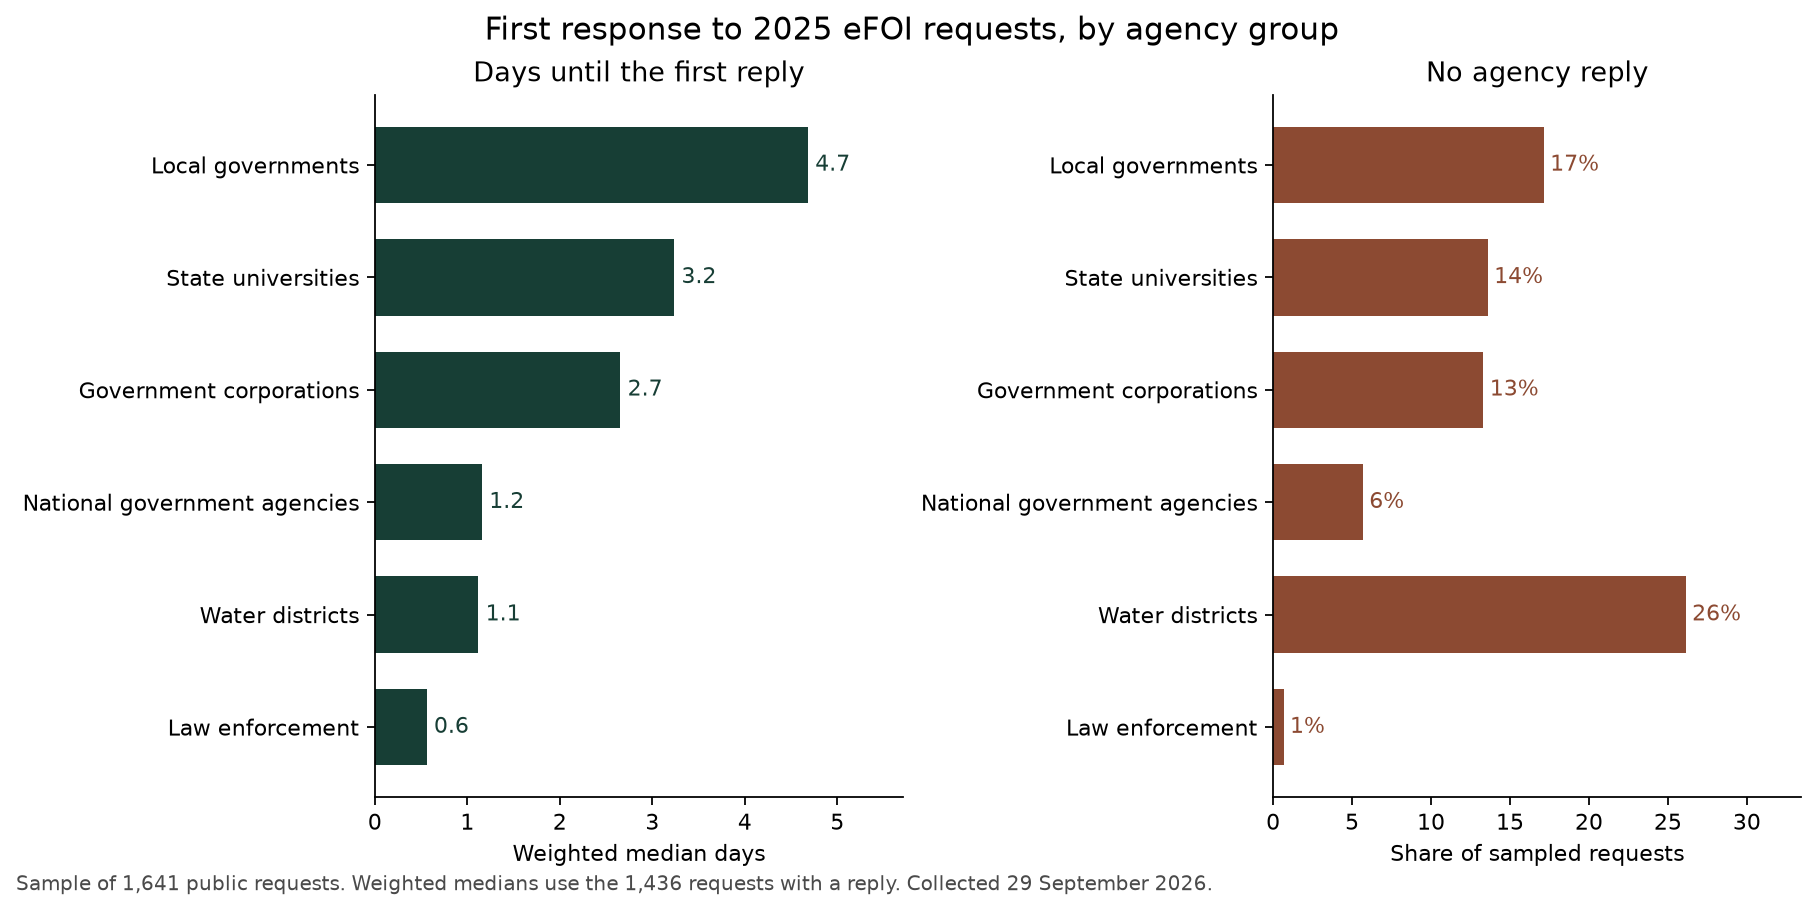

Saved ../reports/figures/rq1_median_and_noreply.png


In [3]:
plot_order = summary.sort_values("weighted_median_days", ascending=True).index.tolist()
plot_labels = [LABELS[group] for group in plot_order]
medians = summary.loc[plot_order, "weighted_median_days"].to_numpy()
no_reply = summary.loc[plot_order, "no_reply_share"].to_numpy() * 100

fig, axes = plt.subplots(1, 2, figsize=(11.2, 5.4), constrained_layout=True)
ink = "#173e35"
accent = "#8c4a32"

axes[0].barh(plot_labels, medians, color=ink, height=0.68)
for i, value in enumerate(medians):
    axes[0].text(value + 0.08, i, f"{value:.1f}", va="center", color=ink, fontsize=10)
axes[0].set_xlabel("Weighted median days")
axes[0].set_title("Days until the first reply")
axes[0].set_xlim(0, max(medians) * 1.22)
axes[0].spines[["top", "right"]].set_visible(False)

axes[1].barh(plot_labels, no_reply, color=accent, height=0.68)
for i, value in enumerate(no_reply):
    axes[1].text(value + 0.4, i, f"{value:.0f}%", va="center", color=accent, fontsize=10)
axes[1].set_xlabel("Share of sampled requests")
axes[1].set_title("No agency reply")
axes[1].set_xlim(0, max(no_reply) * 1.28)
axes[1].spines[["top", "right"]].set_visible(False)

fig.suptitle("First response to 2025 eFOI requests, by agency group", fontsize=14)
fig.text(
    0,
    -0.02,
    f"Sample of {len(sample):,} public requests. Weighted medians use the "
    f"{int(sample['first_response_days'].notna().sum()):,} requests with a reply. "
    "Collected 29 September 2026.",
    fontsize=9,
    color="#4a4a4a",
)

fig_dir = ROOT / "reports" / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
median_path = fig_dir / "rq1_median_and_noreply.png"
fig.savefig(median_path, dpi=160, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(median_path)))
print(f"Saved {median_path.as_posix()}")

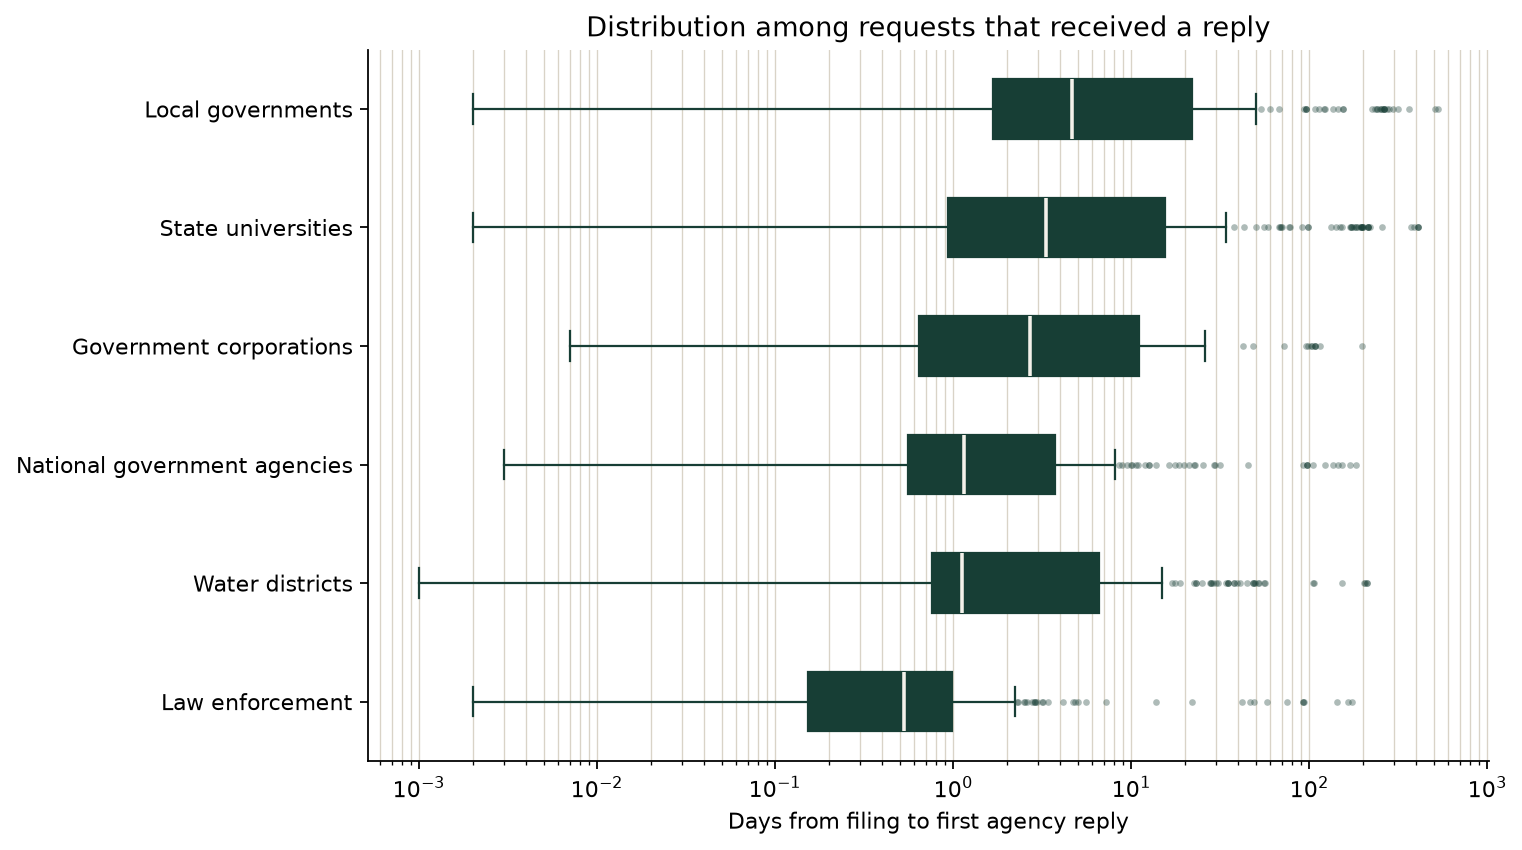

Saved ../reports/figures/rq1_response_time_distribution.png


In [4]:
replied = sample.loc[sample["first_response_days"].notna()].copy()
box_order = plot_order
box_data = [
    replied.loc[replied["agency_group"] == group, "first_response_days"].to_numpy()
    for group in box_order
]

fig, ax = plt.subplots(figsize=(9.4, 5.2), constrained_layout=True)
box = ax.boxplot(
    box_data,
    orientation="horizontal",
    tick_labels=[LABELS[group] for group in box_order],
    patch_artist=True,
    showfliers=True,
    medianprops={"color": "#f4f1ea", "linewidth": 1.6},
    whiskerprops={"color": ink},
    capprops={"color": ink},
    flierprops={"marker": "o", "markersize": 3, "markerfacecolor": ink, "markeredgecolor": "none", "alpha": 0.35},
)
for patch in box["boxes"]:
    patch.set_facecolor(ink)
    patch.set_edgecolor(ink)
ax.set_xscale("log")
ax.set_xlabel("Days from filing to first agency reply")
ax.set_title("Distribution among requests that received a reply")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", which="both", color="#d9d3c7", linewidth=0.6)

dist_path = fig_dir / "rq1_response_time_distribution.png"
fig.savefig(dist_path, dpi=160, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(dist_path)))
print(f"Saved {dist_path.as_posix()}")

## Kruskal–Wallis test

The test uses only requests that got a reply and asks whether response-time ranks differ by agency group, with ε² giving the share of rank variation that goes with the grouping, from 0 to 1. We also run a separate chi-square test on whether the chance of getting any reply differs by group, which gives context for the medians but isn't the test of H₀.

In [5]:
grouped = [
    sample.loc[
        (sample["agency_group"] == group) & sample["first_response_days"].notna(),
        "first_response_days",
    ].to_numpy()
    for group in GROUP_ORDER
]
h_stat, p_value = kruskal(*grouped)
n_replied = sum(len(values) for values in grouped)
k = len(grouped)
epsilon_sq = h_stat * (n_replied + 1) / (n_replied**2 - 1)

print(f"Kruskal-Wallis H = {h_stat:.2f}")
print(f"Groups = {k}, requests with a reply = {n_replied:,}")
print(f"p = {p_value:.4g}")
print(f"epsilon-squared = {epsilon_sq:.3f}")

reply_table = pd.crosstab(
    sample["agency_group"],
    sample["first_response_days"].notna(),
).reindex(GROUP_ORDER)
reply_table.columns = ["no reply", "replied"]
chi2, chi_p, dof, expected = chi2_contingency(reply_table)
print()
print(f"Chi-square for any reply by group: chi2 = {chi2:.2f}, df = {dof}, p = {chi_p:.4g}")
print(f"Smallest expected count: {expected.min():.1f}")
display(reply_table)

Kruskal-Wallis H = 218.71
Groups = 6, requests with a reply = 1,436
p = 2.801e-45
epsilon-squared = 0.152

Chi-square for any reply by group: chi2 = 100.94, df = 5, p = 3.344e-20
Smallest expected count: 21.9


,no reply,replied
agency_group,,
NGA,17,281
GOCC,40,260
SUC,41,260
WATER-DISTRICT,75,212
LGU,30,145
LEA,2,278


## Which groups differ

We run a Mann–Whitney test on every pair of groups and multiply each p-value by 15, the number of pairs (a Bonferroni adjustment), so a pair counts as different only when its adjusted p-value is below 0.05.

In [6]:
pairs = []
for i, left in enumerate(GROUP_ORDER):
    for right in GROUP_ORDER[i + 1:]:
        left_rows = sample.loc[
            (sample["agency_group"] == left) & sample["first_response_days"].notna()
        ]
        right_rows = sample.loc[
            (sample["agency_group"] == right) & sample["first_response_days"].notna()
        ]
        result = mannwhitneyu(
            left_rows["first_response_days"],
            right_rows["first_response_days"],
            alternative="two-sided",
        )
        pairs.append({
            "group_a": left,
            "group_b": right,
            "median_a": weighted_median(left_rows["first_response_days"], left_rows["sampling_weight"]),
            "median_b": weighted_median(right_rows["first_response_days"], right_rows["sampling_weight"]),
            "p": result.pvalue,
        })

pair_table = pd.DataFrame(pairs)
pair_table["p_bonferroni"] = (pair_table["p"] * len(pair_table)).clip(upper=1)
pair_table = pair_table.sort_values("p")
shown_pairs = pair_table.copy()
shown_pairs["median_a"] = shown_pairs["median_a"].round(2)
shown_pairs["median_b"] = shown_pairs["median_b"].round(2)
for column in ("p", "p_bonferroni"):
    shown_pairs[column] = shown_pairs[column].map(lambda value: f"{value:.3g}")
display(shown_pairs)

,group_a,group_b,median_a,median_b,p,p_bonferroni
14,LGU,LEA,4.68,0.56,1.34e-29,2.01e-28
11,SUC,LEA,3.24,0.56,4.81e-28,7.22e-27
8,GOCC,LEA,2.65,0.56,9.99e-22,1.5e-20
13,WATER-DISTRICT,LEA,1.12,0.56,3.19e-20,4.78e-19
4,NGA,LEA,1.16,0.56,2.83e-14,4.25e-13
3,NGA,LGU,1.16,4.68,1.88e-12,2.81e-11
1,NGA,SUC,1.16,3.24,1.63e-08,2.44e-07
12,WATER-DISTRICT,LGU,1.12,4.68,1.1e-06,1.65e-05
7,GOCC,LGU,2.65,4.68,2.93e-05,0.00044
0,NGA,GOCC,1.16,2.65,0.000381,0.00571


## What this says about the question

In [7]:
fastest = summary["weighted_median_days"].idxmin()
slowest = summary["weighted_median_days"].idxmax()
print(
    f"The shortest weighted median wait is {summary.loc[fastest, 'weighted_median_days']:.1f} days "
    f"({LABELS[fastest]}). The longest is {summary.loc[slowest, 'weighted_median_days']:.1f} days "
    f"({LABELS[slowest]})."
)
print(
    f"The no-reply share runs from {summary['no_reply_share'].min():.1%} "
    f"for {LABELS[summary['no_reply_share'].idxmin()]} to "
    f"{summary['no_reply_share'].max():.1%} "
    f"for {LABELS[summary['no_reply_share'].idxmax()]}."
)

if p_value < ALPHA:
    print(
        f"Reject H0 at alpha {ALPHA}: H = {h_stat:.2f}, p = {p_value:.4g}, "
        f"epsilon-squared = {epsilon_sq:.3f}. At least one agency group differs."
    )
else:
    print(
        f"Do not reject H0 at alpha {ALPHA}: H = {h_stat:.2f}, p = {p_value:.4g}."
    )

significant = pair_table.loc[pair_table["p_bonferroni"] < ALPHA]
if significant.empty:
    print("No pair remains significant after the Bonferroni adjustment.")
else:
    print(f"{len(significant)} of {len(pair_table)} pairs remain significant after Bonferroni:")
    for row in significant.itertuples(index=False):
        print(
            f"- {LABELS[row.group_a]} ({row.median_a:.1f} days) vs "
            f"{LABELS[row.group_b]} ({row.median_b:.1f} days), "
            f"adjusted p = {row.p_bonferroni:.4g}"
        )

if chi_p < ALPHA:
    print(
        f"The chance of any reply also differs by group "
        f"(chi-square = {chi2:.2f}, df = {dof}, p = {chi_p:.4g})."
    )
else:
    print(
        f"The chance of any reply does not differ by group at alpha {ALPHA} "
        f"(chi-square = {chi2:.2f}, p = {chi_p:.4g})."
    )

The shortest weighted median wait is 0.6 days (Law enforcement). The longest is 4.7 days (Local governments).
The no-reply share runs from 0.7% for Law enforcement to 26.1% for Water districts.
Reject H0 at alpha 0.05: H = 218.71, p = 2.801e-45, epsilon-squared = 0.152. At least one agency group differs.
11 of 15 pairs remain significant after Bonferroni:
- Local governments (4.7 days) vs Law enforcement (0.6 days), adjusted p = 2.011e-28
- State universities (3.2 days) vs Law enforcement (0.6 days), adjusted p = 7.22e-27
- Government corporations (2.7 days) vs Law enforcement (0.6 days), adjusted p = 1.499e-20
- Water districts (1.1 days) vs Law enforcement (0.6 days), adjusted p = 4.778e-19
- National government agencies (1.2 days) vs Law enforcement (0.6 days), adjusted p = 4.245e-13
- National government agencies (1.2 days) vs Local governments (4.7 days), adjusted p = 2.813e-11
- National government agencies (1.2 days) vs State universities (3.2 days), adjusted p = 2.438e-07
- Wat